In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#Cargar dataset
df = pd.read_csv("Fortnite Statistics.csv")


In [6]:
#Limpiar datos
df['Accuracy'] = df['Accuracy'].str.replace('%', '').astype(float)


In [7]:
#Elegir variables
X = df[['Hits', 'Accuracy', 'Damage to Players']] 

Y = df['Eliminations'] 

#Sacar datos de entorno y prueba
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, Y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.01,-0.02, 0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Hits','Accuracy','Damage to Players']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2927
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [8]:
print("Coeficientes del modelo:")
for col, coef in zip(X.columns, modelo.coef_):
    print(f"{col}: {coef:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")

Coeficientes del modelo:
Hits: 0.0086
Accuracy: -0.0179
Damage to Players: 0.0041
Intercepto: 0.2927


In [9]:
nuevos_datos = np.array([[50, 30, 800]]) 
prediccion = modelo.predict(nuevos_datos)
print(f"\nPredicción de Eliminaciones para [50 Hits, 30% Acc, 800 Dmg]: {prediccion[0]:.2f}")


Predicción de Eliminaciones para [50 Hits, 30% Acc, 800 Dmg]: 3.49


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [10]:
Y_pred = modelo.predict(X_test)
print(f"\nError Cuadrático Medio (MSE): {mean_squared_error(Y_test, Y_pred):.2f}")
print(f"Coeficiente de Determinación (R2): {r2_score(Y_test, Y_pred):.2f}")


Error Cuadrático Medio (MSE): 0.90
Coeficiente de Determinación (R2): 0.69


C:\Users\USER\AppData\Local\Temp\ipykernel_23996\1106989310.py:3: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], 'k--', lw=2, color='red') # Línea ideal


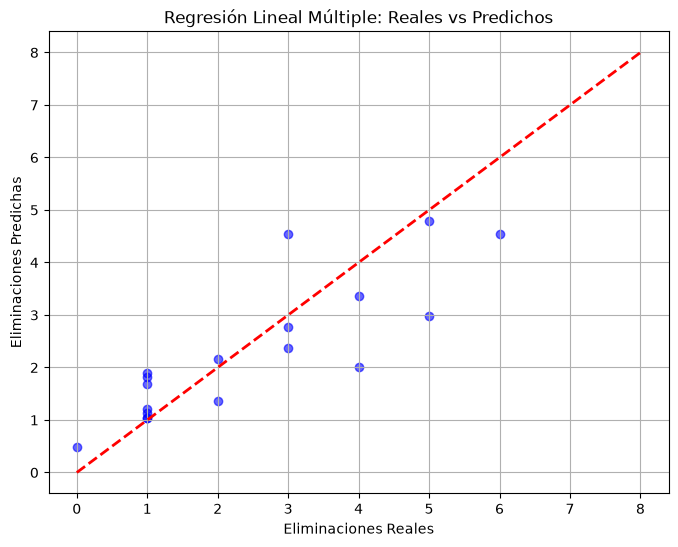

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred, color='blue', alpha=0.6)
plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], 'k--', lw=2, color='red') 
plt.xlabel('Eliminaciones Reales')
plt.ylabel('Eliminaciones Predichas')
plt.title('Regresión Lineal Múltiple: Reales vs Predichos')
plt.grid(True)
plt.show()

Ecuación: Z = -0.12 + -0.0015*Hits + 0.0046*Damage


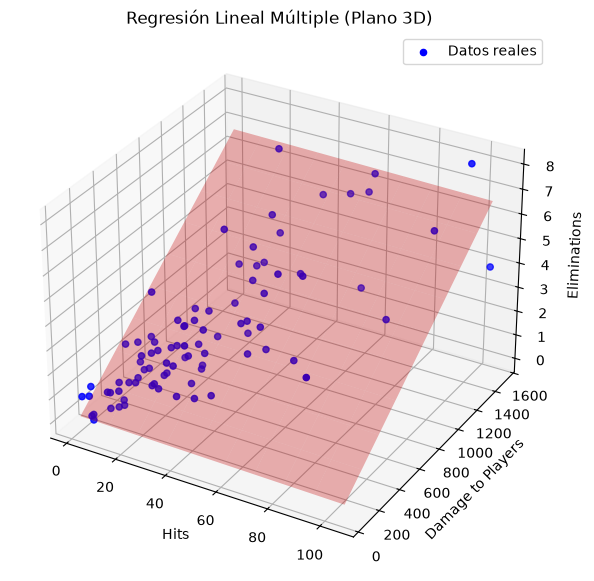

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D  # Para gráficos 3D

# 1. Cargar datos
df = pd.read_csv("Fortnite Statistics.csv")

X = df[['Hits', 'Damage to Players']]  
Z = df['Eliminations']                 

# 3. Entrenar el modelo de Regresión Lineal Múltiple
modelo = LinearRegression()
modelo.fit(X, Z)

# 4. Ver la ecuación del plano
print(f"Ecuación: Z = {modelo.intercept_:.2f} + {modelo.coef_[0]:.4f}*Hits + {modelo.coef_[1]:.4f}*Damage")

# 5. Crear gráfico 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Puntos reales
ax.scatter(df['Hits'], df['Damage to Players'], df['Eliminations'], color='blue', label='Datos reales')

# Crear una malla para dibujar el plano de regresión
x_surf, y_surf = np.meshgrid(np.linspace(df['Hits'].min(), df['Hits'].max(), 10),
                             np.linspace(df['Damage to Players'].min(), df['Damage to Players'].max(), 10))
z_surf = modelo.intercept_ + modelo.coef_[0]*x_surf + modelo.coef_[1]*y_surf

# Dibujar el plano
ax.plot_surface(x_surf, y_surf, z_surf, color='red', alpha=0.3)

ax.set_xlabel('Hits')
ax.set_ylabel('Damage to Players')
ax.set_zlabel('Eliminations')
ax.set_title('Regresión Lineal Múltiple (Plano 3D)')
plt.legend()
plt.show()

In [ ]:
#DEBER 3